In [26]:
import pandas as pd
import sqlite3 as sq
import matplotlib as mpl
from matplotlib import rcParams
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import fiona
import os
import io
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.functions import read_census_table, read_wp23_table

Read in and format dataframes

In [27]:
#TN we're reading in from UrbanSIM
tnurbansim = pd.read_csv(r"G:\3-GitHub\FCLUCS_Scenario_Planning\1-data\1-raw\2050RTP-TDMFeedback_2050Block.csv")

In [28]:
col_dict = {'sector_0': 'EMP_OTHER', 'sector_1': 'EMP_SERVICE', 'sector_2': 'EMP_RETAIL', 'sector_3': 'EMP_OFFICE', 'geo_level_id': 'GEO_ID',
               'sector_4': 'EMP_MEDICAL', 'sector_5': 'EMP_INDUSTRIAL', 'sector_6': 'EMP_GOVERNMENT', 'sector_7': 
               'EMP_FOODSERVICE', 'sector_8': 'EMP_EDUCATION', 'household_population': 'HHPOP', 'sum_total_households': 'HH', 'sum_total_jobs': 'EMP'}
tnurbansim = tnurbansim.rename(columns = col_dict)
tnurbansim_filt = tnurbansim[['GEO_ID', 'HHPOP']]

In [29]:
tnurbansim_filt.head(2)

,GEO_ID,HHPOP
0,470831203003000,16.582708
1,470831203003090,0.231629


In [30]:
tnurbansim_filt['GEO_ID'] = tnurbansim_filt['GEO_ID'].astype(str)

In [31]:
#KY we will take the same 2020 allocations that we used for 2023 base year to dole out the change in population between this and the 2050 controls,
# so read in the base year with allocations as well as the WP smoothed totals
ky = gpd.read_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\1-data\2-interim\BaseYear.gpkg", layer="KY_HHPOP")
kycontrols = read_wp23_table('DemSmoothed')

In [32]:
kycontrols.head(1)

,NAME,Variable,2023 Census,2023 WP,2024,2025,2026,2027,2028,2029,...,2042,2043,2044,2045,2046,2047,2048,2049,2050,Last Update Pushed_20260812
0,"Cannon County, Tennessee",Population,15063,14854.0,15122.259259,15180.518519,15239.777778,15300.037037,15359.296296,15419.555556,...,16232.925926,16297.185185,16362.444444,16427.703704,16492.962963,16559.222222,16625.481481,16691.740741,16759.0,None


In [33]:
thelist = ['Trigg County, Kentucky', 'Christian County, Kentucky']
kyhorizon = kycontrols[['NAME', '2023 Census', '2050']].loc[kycontrols['NAME'].isin(thelist)]
kyhorizon['HHPOP_GROWTH'] = kyhorizon['2050'] - kyhorizon['2023 Census']

In [34]:
kyhorizon.head(2)

,NAME,2023 Census,2050,HHPOP_GROWTH
17,"Christian County, Kentucky",72032,70260.0,-1772.0
19,"Trigg County, Kentucky",14369,16279.0,1910.0


In [35]:
trigghorizoncontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Trigg County, Kentucky', '2050'].iloc[0])
christianhorizoncontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Christian County, Kentucky', '2050'].iloc[0])
triggcontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Trigg County, Kentucky', '2023 Census'].iloc[0])
christiancontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Christian County, Kentucky', '2023 Census'].iloc[0])
triggdiff = int(kyhorizon.loc[kyhorizon['NAME'] == 'Trigg County, Kentucky', 'HHPOP_GROWTH'].iloc[0])
christiandiff = int(kyhorizon.loc[kyhorizon['NAME'] == 'Christian County, Kentucky', 'HHPOP_GROWTH'].iloc[0])

In [36]:
controls = {'Trigg County, Kentucky': trigghorizoncontrol,'Christian County, Kentucky': christianhorizoncontrol}

ky['HHPOP_2050'] = ((ky['HHPOP_ALLOC'])/100) * ky['COUNTY'].map(controls)

In [37]:
ky.loc[ky['COUNTY'] == 'Trigg County, Kentucky', 'HHPOP_2050'].sum()

np.float64(16279.0)

In [38]:
# ============================================================
# 1. LOCAL GROWTH INPUTS
# ============================================================

# GEO_ID: additional household population expected by 2050
# Replace examples with actual stakeholder inputs.
# Leave empty if no local growth has been identified.

local_growth = {
    # "210470000000000": 150,
    # "212210000000000": 100,
}


def apply_local_growth(gdf, growth_dict):
    """
    Apply locally identified 2020-2050 household population increases.

    Local growth is additive to the 2020 baseline and protected
    from background population decline.

    Parameters
    ----------
    gdf : GeoDataFrame
        Census blocks with GEO_ID and HHPOP.

    growth_dict : dict
        {GEO_ID: additional household population}

    Returns
    -------
    GeoDataFrame
        With LOCAL_GROWTH and HHPOP_GROWTH_BASE columns.
    """

    gdf = gdf.copy()

    # Normalize GEOIDs
    gdf["GEO_ID"] = gdf["GEO_ID"].astype(str).str.strip()

    growth_dict = {
        str(k).strip(): v for k, v in growth_dict.items()
    }

    # Validate GEOIDs
    if gdf["GEO_ID"].duplicated().any():
        raise ValueError("Duplicate GEO_ID values found.")

    missing = set(growth_dict) - set(gdf["GEO_ID"])

    if missing:
        raise ValueError(
            f"Local growth GEOIDs not found: {sorted(missing)}"
        )

    # Validate growth values
    for geoid, value in growth_dict.items():
        if (
            not isinstance(value, (int, float, np.number))
            or not np.isfinite(value)
            or value < 0
        ):
            raise ValueError(
                f"Invalid local growth for {geoid}: {value}"
            )

    # Apply local growth
    gdf["LOCAL_GROWTH"] = (
        gdf["GEO_ID"]
        .map(growth_dict)
        .fillna(0)
        .astype(float)
    )

    # Adjusted population used for density and adjacency
    gdf["HHPOP_GROWTH_BASE"] = (
        gdf["HHPOP"] + gdf["LOCAL_GROWTH"]
    )

    return gdf


# ============================================================
# 2. PREPARE DATA
# ============================================================

ky = ky.copy().reset_index(drop=True)

# Preserve original 2050 allocation
ky["HHPOP_2050_ORIG"] = ky["HHPOP_2050"].copy()

# Apply local growth BEFORE spatial calculations
ky = apply_local_growth(ky, local_growth)

# Calculate block area in square miles
ky_proj = ky.to_crs("EPSG:5070")

ky["AREA_SQMI"] = (
    ky_proj.geometry.area / 2_589_988.11
)

# Household population density including local development
ky["HHPOP_DENSITY"] = (
    ky["HHPOP_GROWTH_BASE"]
    / ky["AREA_SQMI"].replace(0, np.nan)
)

# Original zero-population blocks
ky["ZERO_POP"] = ky["HHPOP"] == 0


# ============================================================
# 3. IDENTIFY HIGH-DENSITY BLOCKS
# ============================================================

ky["HIGH_DENSITY"] = False

for county, group in ky.groupby("COUNTYFP"):

    # Use populated blocks in the adjusted distribution
    populated = group.loc[
        (group["HHPOP_GROWTH_BASE"] > 0) &
        (group["HHPOP_DENSITY"].notna())
    ]

    if populated.empty:
        continue

    threshold = populated["HHPOP_DENSITY"].quantile(0.75)

    ky.loc[
        populated.index,
        "HIGH_DENSITY"
    ] = (
        populated["HHPOP_DENSITY"] >= threshold
    )


# ============================================================
# 4. IDENTIFY ADJACENT ZERO-POPULATION BLOCKS
# ============================================================

ky["_block_id"] = np.arange(len(ky))

# Zero-population blocks without specified local growth
zero_blocks = ky.loc[
    (ky["ZERO_POP"]) &
    (ky["LOCAL_GROWTH"] == 0)
].copy()

high_blocks = ky.loc[
    ky["HIGH_DENSITY"]
].copy()

# Identify touching blocks (queen contiguity)
adjacent = gpd.sjoin(
    zero_blocks,
    high_blocks[
        [
            "_block_id",
            "COUNTYFP",
            "HHPOP_GROWTH_BASE",
            "geometry"
        ]
    ],
    how="inner",
    predicate="touches",
    lsuffix="zero",
    rsuffix="high"
)

# Keep adjacency within county boundaries
adjacent = adjacent.loc[
    adjacent["COUNTYFP_zero"] ==
    adjacent["COUNTYFP_high"]
].copy()

# Sum adjusted population of neighboring high-density blocks
weights = (
    adjacent
    .groupby("_block_id_zero")["HHPOP_GROWTH_BASE_high"]
    .sum()
    .rename("ADJ_POP")
)

ky["ADJ_POP"] = (
    ky["_block_id"]
    .map(weights)
    .fillna(0)
)

# Eligible for additional spatial expansion
ky["ELIGIBLE"] = (
    ky["ZERO_POP"] &
    (ky["LOCAL_GROWTH"] == 0) &
    (ky["ADJ_POP"] > 0)
)


# ============================================================
# 5. ALLOCATE 2050 HOUSEHOLD POPULATION
# ============================================================

# Start with 2020 population plus locally identified growth
ky["HHPOP_2050_FINAL"] = (
    ky["HHPOP"].astype(float)
    + ky["LOCAL_GROWTH"]
)

ky["BACKGROUND_CHANGE"] = 0.0

for county, idx in ky.groupby("COUNTYFP").groups.items():

    # County controls
    pop_2020 = ky.loc[idx, "HHPOP"].sum()
    pop_2050 = ky.loc[idx, "HHPOP_2050_ORIG"].sum()

    # Local development
    local_total = ky.loc[idx, "LOCAL_GROWTH"].sum()

    # Remaining growth or decline
    remaining_change = (
        pop_2050 - pop_2020 - local_total
    )

    # Existing populated blocks without local growth
    # These are eligible for proportional increases or decreases
    existing_idx = ky.loc[idx].index[
        (ky.loc[idx, "HHPOP"] > 0) &
        (ky.loc[idx, "LOCAL_GROWTH"] == 0)
    ]

    # Zero-population blocks eligible for spatial expansion
    eligible_idx = ky.loc[idx].index[
        ky.loc[idx, "ELIGIBLE"]
    ]

    # --------------------------------------------------------
    # POSITIVE REMAINING GROWTH
    # --------------------------------------------------------

    if remaining_change > 0:

        # Allocate 5% to eligible zero-population blocks
        if len(eligible_idx) > 0:
            zero_growth = remaining_change * 0.05
        else:
            zero_growth = 0

        existing_growth = remaining_change - zero_growth

        # Distribute remaining growth to existing blocks
        if existing_growth > 0:

            weights = ky.loc[existing_idx, "HHPOP"]

            if weights.sum() <= 0:
                raise ValueError(
                    f"No populated blocks available for "
                    f"background growth in county {county}"
                )

            ky.loc[
                existing_idx, "BACKGROUND_CHANGE"
            ] = (
                weights / weights.sum()
                * existing_growth
            )

        # Allocate spatial expansion
        if zero_growth > 0:

            weights = ky.loc[eligible_idx, "ADJ_POP"]

            ky.loc[
                eligible_idx, "BACKGROUND_CHANGE"
            ] = (
                weights / weights.sum()
                * zero_growth
            )

    # --------------------------------------------------------
    # NEGATIVE REMAINING GROWTH / DECLINE
    # --------------------------------------------------------

    elif remaining_change < 0:

        # Decline is assigned only to blocks without local growth
        weights = ky.loc[existing_idx, "HHPOP"]

        if weights.sum() <= 0:
            raise ValueError(
                f"No unprotected population available "
                f"for decline in county {county}"
            )

        # Prevent decline exceeding available population
        if abs(remaining_change) > weights.sum():
            raise ValueError(
                f"Required decline exceeds available "
                f"unprotected population in county {county}. "
                f"Review local growth assumptions."
            )

        ky.loc[
            existing_idx, "BACKGROUND_CHANGE"
        ] = (
            weights / weights.sum()
            * remaining_change
        )

    # Apply background changes
    ky.loc[idx, "HHPOP_2050_FINAL"] += (
        ky.loc[idx, "BACKGROUND_CHANGE"]
    )


# ============================================================
# 6. QUALITY ASSURANCE
# ============================================================

qa = ky.groupby(["COUNTYFP", "COUNTY"]).agg(
    Pop_2020=("HHPOP", "sum"),
    Pop_2050_Control=("HHPOP_2050_ORIG", "sum"),
    Local_Growth=("LOCAL_GROWTH", "sum"),
    Background_Change=("BACKGROUND_CHANGE", "sum"),
    Pop_2050_Final=("HHPOP_2050_FINAL", "sum"),
    Zero_Pop_Blocks=("ZERO_POP", "sum"),
    Eligible_Blocks=("ELIGIBLE", "sum")
)

qa["Net_Growth"] = (
    qa["Pop_2050_Control"] - qa["Pop_2020"]
)

qa["Control_Diff"] = (
    qa["Pop_2050_Final"] - qa["Pop_2050_Control"]
)

qa["Local_Share_of_2050"] = (
    qa["Local_Growth"]
    / qa["Pop_2050_Control"].replace(0, np.nan)
    * 100
)

# Check for negative block populations
if (ky["HHPOP_2050_FINAL"] < -1e-8).any():
    raise ValueError(
        "Negative block populations detected."
    )

# Confirm county controls are preserved
if not np.allclose(
    qa["Pop_2050_Final"],
    qa["Pop_2050_Control"],
    atol=1e-6,
    rtol=0
):
    raise ValueError(
        "Final allocations do not match county controls."
    )

print(qa.round(2))

# Remove temporary join identifier
ky = ky.drop(columns=["_block_id"])


                                     Pop_2020  Pop_2050_Control  Local_Growth  \
COUNTYFP COUNTY                                                                 
21047    Christian County, Kentucky     67114           70260.0           0.0   
21221    Trigg County, Kentucky         14311           16279.0           0.0   

                                     Background_Change  Pop_2050_Final  \
COUNTYFP COUNTY                                                          
21047    Christian County, Kentucky             3146.0         70260.0   
21221    Trigg County, Kentucky                 1968.0         16279.0   

                                     Zero_Pop_Blocks  Eligible_Blocks  \
COUNTYFP COUNTY                                                         
21047    Christian County, Kentucky              655               95   
21221    Trigg County, Kentucky                  413               30   

                                     Net_Growth  Control_Diff  \
COUNTYFP COUNTY     

In [39]:
ky.head(2)

,GEO_ID,COUNTY,COUNTYFP,HHPOP,HHPOP_ALLOC,geometry,HHPOP_2050,HHPOP_2050_ORIG,LOCAL_GROWTH,HHPOP_GROWTH_BASE,AREA_SQMI,HHPOP_DENSITY,ZERO_POP,HIGH_DENSITY,ADJ_POP,ELIGIBLE,HHPOP_2050_FINAL,BACKGROUND_CHANGE
0,212219701003003,"Trigg County, Kentucky",21221,4,0.028594,"POLYGON ((-87.87697 36.96011, -87.87566 36.959...",4.654800,4.654800,0.0,4.0,0.048542,82.403289,False,False,0.0,False,4.522563,0.522563
1,212219701003006,"Trigg County, Kentucky",21221,16,0.114376,"POLYGON ((-87.87628 36.95714, -87.87603 36.957...",18.619201,18.619201,0.0,16.0,0.160488,99.695733,False,False,0.0,False,18.090252,2.090252


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

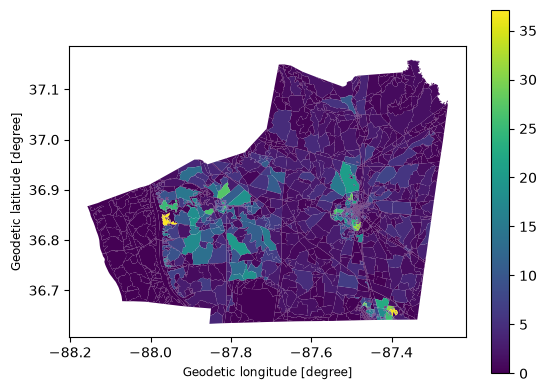

In [40]:
to_viz = 'BACKGROUND_CHANGE'
custom_low = 0
custom_high = 1250
ky.plot(column = to_viz, cmap="viridis", legend=True, 
        #vmin= custom_low,
        vmin = ky[to_viz].min(), 
        #vmax= custom_high
        vmax = ky[to_viz].max(),
        )